In [10]:
import argparse
import json
import pickle
from pathlib import Path

import equinox as eqx
import jax

# Match the x64 setting used by the rest of the pipeline (run_full_gd1_model.py
# enables this at import time), so that a flow trained here can be
# deserialised/used downstream without a dtype (float32 vs float64) mismatch.
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
from astropy.table import Table
from flowjax.bijections import RationalQuadraticSpline
from flowjax.distributions import Normal
from flowjax.flows import masked_autoregressive_flow
from flowjax.train import fit_to_data

import matplotlib.pyplot as plt

In [11]:
# Columns modeled by the flow, in order: (color, magnitude).
EVENT_COLUMNS = ("g0", "r0")
COND_COLUMNS = ("phi1",)
event_dim = len(EVENT_COLUMNS)
cond_dim = len(COND_COLUMNS)

In [15]:
# Load background data

with open('/Users/Tavangar/Work/gd1-dr3/data/post_cats_data_flow_version.pkl', "rb") as f:
    obj = pickle.load(f)

bkg_tbl_ = obj['bkg_data'] if isinstance(obj, dict) else obj
bkg_tbl = bkg_tbl_[(bkg_tbl_['g0'] > 0) & (bkg_tbl_['r0'] > 0) & (bkg_tbl_['g0'] < 22) & (bkg_tbl_['r0'] < 22)]

max_n = None
if max_n is not None and len(bkg_tbl) > max_n:
    rng = np.random.default_rng(42)
    idx = rng.choice(len(bkg_tbl), size=max_n, replace=False)
    idx.sort()
    bkg_tbl = bkg_tbl[idx]


In [16]:
bkg_tbl

source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phot_g_mean_mag,phot_g_mean_flux_over_error,phot_bp_mean_mag,phot_bp_mean_flux_over_error,phot_rp_mean_mag,phot_rp_mean_flux_over_error,phi1,phi2,pm_phi1_cosphi2,pm_phi1_cosphi2_unrefl,pm_phi2,pm_phi2_unrefl,g0,r0,i0,pm1,pm2,pm1_error,pm2_error,rv,rv_err
,,,,,,,,,,,,,,,,,,,,,,,,deg,deg,mas / yr,mas / yr,mas / yr,mas / yr,,,,mas / yr,mas / yr,,,,
int64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
576748068435698048,134.13841688083966,0.744322167695016,0.2984067087733031,0.0703053,-3.8139182053063028,0.06819834,-4.5132924531099246,0.047343124,0.056212936,-0.09234336,-0.020601856,0.16351864,0.03781591,-0.2740701,0.32953483,-0.2281111,-0.08119383,16.797646,1971.64,17.151026,164.42722,16.287083,325.6407,-77.47744548223773,-7.900720690605846,-0.3271128067515927,-5.818653284158339,4.091166779867696,1.0291038833952695,17.046773552894592,16.675229139626026,16.5437056645751,-5.818653284158339,1.0291038833952695,0.05120703960399137,0.06534694961043405,--,--
576748244530543488,134.16732705372561,0.7688112975036265,0.9022941098563593,0.12843332,-0.40705646569708565,0.12549128,-5.993332435999002,0.09447704,0.10845018,-0.046182457,0.07873066,0.022839377,0.057953816,-0.32184994,0.3101018,-0.082185306,-0.13549173,17.862417,983.333,18.390556,70.363174,17.150635,113.5506,-77.44140251696837,-7.913403723893333,0.10736800452494258,-5.385816711955507,0.3998047000599115,-2.6605839584354953,18.410609543323517,17.725450068712234,17.410010389983654,-5.385816711955507,-2.6605839584354953,0.09619484027752398,0.12417941018511514,--,--
576750301818727936,134.22981963824748,0.8305934323875556,0.4623623504038562,0.45960036,-2.7148906452442993,0.44875842,-8.888072858020927,0.3240633,0.0007706698,-0.11292817,-0.07473175,-6.6603854e-05,-0.0378848,-0.19379774,0.32304,-0.05691278,-0.16431886,19.66402,341.23932,20.072033,19.38162,19.151209,24.04379,-77.3557635158985,-7.936359587581789,-3.5507685108418894,-9.047847398107399,0.9346461737887245,-2.122481520693277,19.996709510684013,19.51764164119959,19.389677971601486,-9.047847398107399,-2.122481520693277,0.32956005105413144,0.44473736202940733,--,--
576760064280542592,134.14547166643905,0.7975047222182825,0.2592137893508311,0.08831908,1.2105295907878606,0.0872203,-7.551246770848138,0.06547589,0.13469785,-0.11898727,0.061640035,0.05596912,0.057629358,-0.37289673,0.27530864,-0.11406384,-0.098390386,17.17117,1437.0532,17.464699,136.93924,16.720589,161.62434,-77.42744965924754,-7.880088954961589,-0.4256089948812579,-5.919429382262511,-1.7787087613079242,-4.84221699976619,17.32744286954403,17.07474811375141,16.982228606939316,-5.919429382262511,-4.84221699976619,0.06810065716241248,0.08518669986759567,--,--
576760300502579328,134.1113034294974,0.794208023959123,0.35385377509379856,0.20561622,0.5769673466493516,0.21887752,-6.348265772432951,0.14677288,0.037506532,-0.09349215,0.034810252,0.14303495,0.008036133,-0.31303787,0.18533134,-0.24210013,0.11706651,18.772007,639.3669,19.089333,37.348625,18.310263,63.88456,-77.44766246689005,-7.85221053515438,0.29474835232765395,-5.1981510175750465,-0.6230304482611696,-3.6895251232410406,18.91274820268154,18.65433733165264,18.557800620794296,-5.1981510175750465,-3.6895251232410406,0.17740042797695127,0.19488133932016394,--,--
576760334862325504,134.12016082647645,0.8119471640328474,0.4773120527946953,0.9126172,-1.5999831624839518,0.85187846,-7.606200170886891,0.59411466,-0.13431661,0.19690023,0.19340004,0.013090275,0.051451985,-0.19572237,0.086108655,-0.4635213,0.14878272,20.438293,172.56815,21.22148,7.7923417,19.

In [17]:
columns = {**{c: bkg_tbl[c] for c in EVENT_COLUMNS}, **{c: bkg_tbl[c] for c in COND_COLUMNS}}

norm_stats = {}
standardized = {}
for name, col in columns.items():
    arr = np.asarray(col, dtype="f8")
    mean, std = float(np.mean(arr)), float(np.std(arr))
    norm_stats[name] = {"mean": mean, "std": std}
    standardized[name] = (arr - mean) / std

target = jnp.stack([jnp.asarray(standardized[c]) for c in EVENT_COLUMNS], axis=-1)
condition = jnp.stack([jnp.asarray(standardized[c]) for c in COND_COLUMNS], axis=-1)


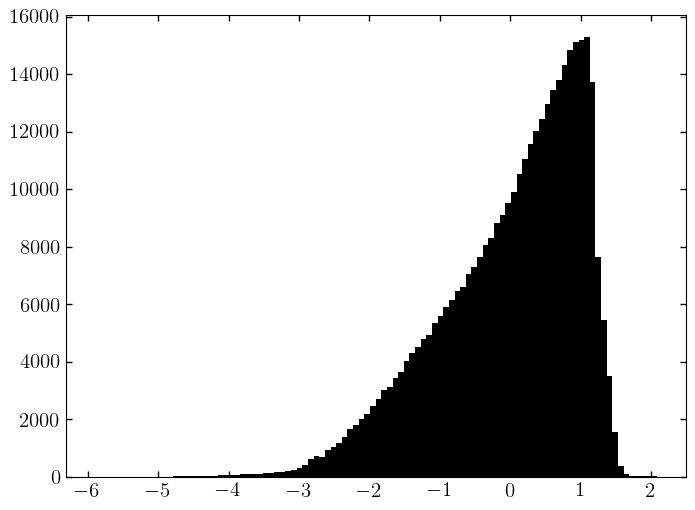

array([-5.91175187, -5.4082971 , -5.23323987, -5.19393367, -5.13965254,
       -5.10006007, -5.07040861, -5.06954748, -5.05957547, -5.02955339,
       -5.02439007, -4.95412984, -4.93448437, -4.92486671, -4.88605107])

In [23]:
plt.hist(target[:, 1], bins=100)
plt.show()
np.sort(target[:, 1])[:15]

In [11]:
key = jax.random.key(42)
key, subkey_flow, subkey_train, subkey_diag = jax.random.split(key, 4)

In [12]:
"""
Construct an (untrained) conditional masked-autoregressive flow.

Uses a rational-quadratic-spline (neural spline flow) transformer rather
than flowjax's default affine transformer. The default affine transformer
has an unconstrained (only lower-bounded) scale, and empirically produced
wildly exploding samples (e.g. |value| ~ 1e6-1e7 in standardized units)
for this data, likely from under-trained regions of conditioning space
driving the exponentiated scale to extreme values. The spline transformer
is identity outside of ``[-rqs_interval, rqs_interval]``, which keeps
samples/log_probs numerically stable, and is standard practice for
conditional density estimation with normalizing flows. Since inputs are
standardized to zero mean/unit variance (see ``prepare_training_arrays``),
an interval of a few sigma comfortably covers the bulk of the data.
"""

rqs_knots = 8 # number of knots for the rational-quadratic spline TODO: WHAT IS THIS?
rqs_interval = 5.0 # interval for the rational-quadratic spline TODO: WHAT IS THIS?

transformer = RationalQuadraticSpline(knots=rqs_knots, interval=rqs_interval)

flow_layers = 8 # number of stacked masked-autoregressive transform layers composed together
nn_width = 50 # the number of hidden units per layer
nn_depth = 1 # number of hidden layers in that conditioner network
flow = masked_autoregressive_flow(
        subkey_flow,
        base_dist=Normal(jnp.zeros(event_dim)),
        transformer=transformer,
        cond_dim=cond_dim,
        flow_layers=flow_layers,
        nn_width=nn_width,
        nn_depth=nn_depth,
    )

In [17]:
learning_rate = 5e-4 # step size for the (usually Adam-based) gradient-based optimizer 
                     #  maximizing the log-likelihood of the training data under the flow
max_epochs = 200 # caps the number of full passes over the training data
max_patience = 10 # training halts if the validation loss hasn't improved for this many consecutive epochs
batch_size = 256 # minibatch size used for each stochastic gradient step
val_prop = 0.1 # the fraction of the (already subsampled, up to 100k) training rows held out as a 
               #  validation set purely to drive the max_patience early-stopping criterion
show_progress = True

trained_flow, losses = fit_to_data(
    subkey_train,
    flow,
    (target, condition),
    learning_rate=learning_rate,
    max_epochs=max_epochs,
    max_patience=max_patience,
    batch_size=batch_size,
    val_prop=val_prop,
    show_progress=show_progress,
)

 19%|█▉        | 38/200 [01:04<04:36,  1.70s/it, train=0.518, val=0.534 (Max patience reached)]


In [14]:
print(f"  final train loss: {losses['train'][-1]:.4f}")
print(f"  final val loss:   {losses['val'][-1]:.4f}")

  final train loss: 0.5047
  final val loss:   0.5140


In [7]:
target

NameError: name 'target' is not defined

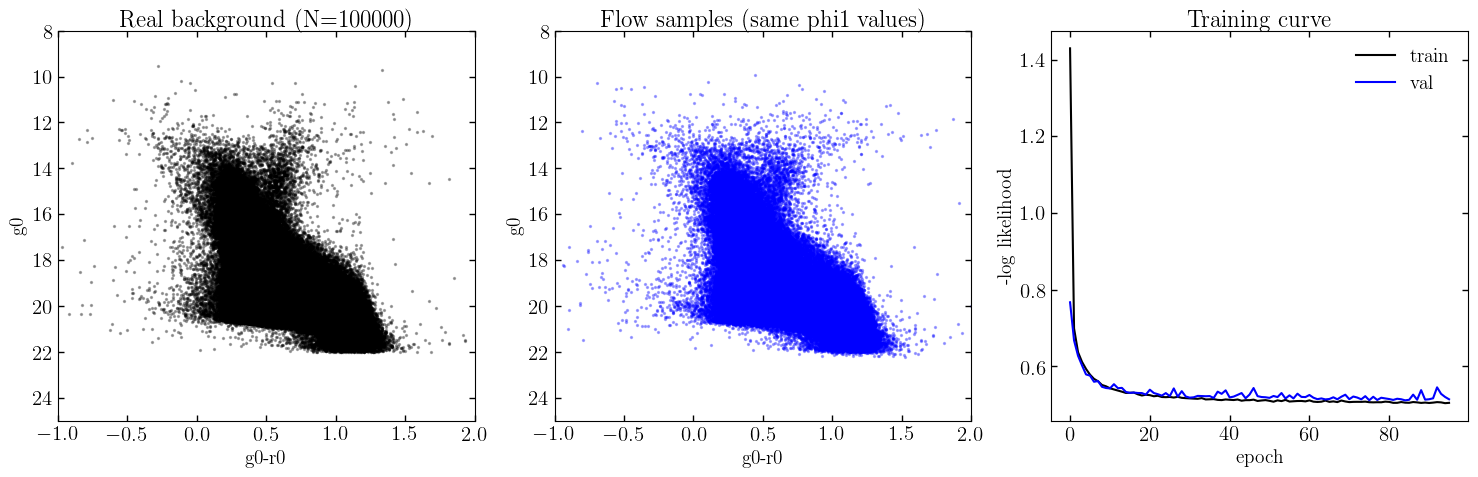

In [15]:
n_draw = target.shape[0]
# Sample the flow at the same conditioning (phi1) values as the real data,
# so the two panels are directly comparable.
samples = jax.vmap(lambda k, c: trained_flow.sample(k, condition=c))(
    jax.random.split(key, n_draw), condition
)

def unstd(name, arr):
    s = norm_stats[name]
    return arr * s["std"] + s["mean"]

real_g0 = unstd("g0", np.asarray(target[:, 0]))
real_r0 = unstd("r0", np.asarray(target[:, 1]))
flow_g0 = unstd("g0", np.asarray(samples[:, 0]))
flow_r0 = unstd("r0", np.asarray(samples[:, 1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(real_g0 - real_r0, real_g0, s=2, alpha=0.3, rasterized=True)
axes[0].set_title(f"Real background (N={n_draw})")

axes[1].scatter(flow_g0 - flow_r0, flow_g0, s=2, alpha=0.3, color="C1", rasterized=True)
axes[1].set_title("Flow samples (same phi1 values)")

for ax in axes[:2]:
    ax.set_xlabel("g0-r0")
    ax.set_ylabel("g0")
    ax.invert_yaxis()
    ax.set_xlim(-1, 2)
    ax.set_ylim(25, 8)

axes[2].plot(losses["train"], label="train")
axes[2].plot(losses["val"], label="val")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("-log likelihood")
axes[2].set_title("Training curve")
axes[2].legend()

fig.tight_layout()
# fig.savefig(out_path, dpi=150)
plt.show()

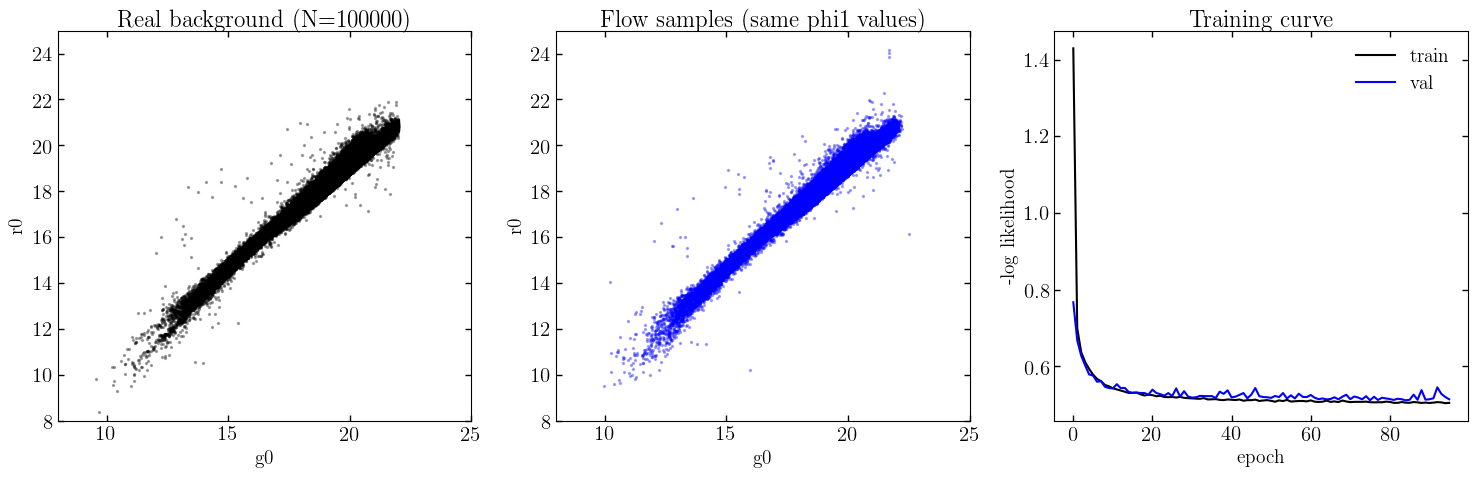

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(real_g0, real_r0, s=2, alpha=0.3, rasterized=True)
axes[0].set_title(f"Real background (N={n_draw})")

axes[1].scatter(flow_g0, flow_r0, s=2, alpha=0.3, color="C1", rasterized=True)
axes[1].set_title("Flow samples (same phi1 values)")

for ax in axes[:2]:
    ax.set_xlabel("g0")
    ax.set_ylabel("r0")
    ax.set_xlim(8, 25)
    ax.set_ylim(8, 25)

axes[2].plot(losses["train"], label="train")
axes[2].plot(losses["val"], label="val")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("-log likelihood")
axes[2].set_title("Training curve")
axes[2].legend()

fig.tight_layout()
# fig.savefig(out_path, dpi=150)
plt.show()

In [ ]:
eqx.tree_serialise_leaves(out_prefix.with_suffix(".eqx"), flow)
meta = {
    "flow_kwargs": flow_kwargs,
    "norm_stats": norm_stats,
    "event_columns": list(EVENT_COLUMNS),
    "cond_columns": list(COND_COLUMNS),
}
with open(f"{out_prefix}_meta.json", "w") as f:
    json.dump(meta, f, indent=2)